In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel('UScereal.xlsx')
df['vitamins'] = df['vitamins'].replace({1: '100%', '1': '100%'})

print("Dataset Shape: {}".format(df.shape))
df.head()

Dataset Shape: (65, 12)


,Name,mfr,calories,protein,fat,sodium,fibre,carbo,sugars,shelf,potassium,vitamins
0,100% Bran,N,212.12,12.12,3.03,393.94,30.30,15.15,18.18,3,848.48,enriched
1,All-Bran,K,212.12,12.12,3.03,787.88,27.27,21.21,15.15,3,969.70,enriched
2,All-Bran with Extra Fiber,K,100.00,8.00,0.00,280.00,28.00,16.00,0.00,3,660.00,enriched
3,Apple Cinnamon Cheerios,G,146.67,2.67,2.67,240.00,2.00,14.00,13.33,1,93.33,enriched
4,Apple Jacks,K,110.00,2.00,0.00,125.00,1.00,11.00,14.00,2,30.00,enriched


In [2]:
summary_stats = df.describe()
summary_stats

,calories,protein,fat,sodium,fibre,carbo,sugars,shelf,potassium
count,65.000000,65.000000,65.000000,65.000000,65.000000,65.000000,65.000000,65.000000,65.000000
mean,149.408615,3.684000,1.422462,237.838308,3.870923,19.967538,10.051077,2.169231,159.119692
std,62.411936,2.642821,1.647561,130.629537,6.133094,8.468190,5.835252,0.839815,180.288575
min,50.000000,0.750000,0.000000,0.000000,0.000000,10.530000,0.000000,1.000000,15.000000
25%,110.000000,2.000000,0.000000,180.000000,0.000000,15.000000,4.000000,1.000000,45.000000
50%,134.330000,3.000000,1.000000,232.000000,2.000000,18.670000,12.000000,2.000000,96.590000
75%,179.100000,4.480000,2.000000,290.000000,4.480000,22.390000,14.000000,3.000000,220.000000
max,440.000000,12.120000,9.090000,787.880000,30.300000,68.000000,20.900000,3.000000,969.700000


In [3]:
missing_values = df.isnull().sum()
print("Missing values in each column:\n{}".format(missing_values))

if missing_values.sum() == 0:
    print("\nConclusion: There are NO missing values in the dataset.")
else:
    print("\nConclusion: Missing values are present.")

Missing values in each column:
Name         0
mfr          0
calories     0
protein      0
fat          0
sodium       0
fibre        0
carbo        0
sugars       0
shelf        0
potassium    0
vitamins     0
dtype: int64

Conclusion: There are NO missing values in the dataset.


In [4]:
avg_protein = df.groupby('mfr')['protein'].mean()
print("Average Protein (grams) by Manufacturer:")
print(avg_protein)

Average Protein (grams) by Manufacturer:
mfr
G    2.885000
K    3.919048
N    7.026667
P    4.698889
Q    3.460000
R    2.604000
Name: protein, dtype: float64


In [5]:
g_cereals = df[df['mfr'] == 'G']
max_sugar_row = g_cereals.loc[g_cereals['sugars'].idxmax()]

print("Highest Sugar Cereal from Manufacturer G:")
print("Name: {}".format(max_sugar_row['Name']))
print("Sugar Content: {} grams".format(max_sugar_row['sugars']))

Highest Sugar Cereal from Manufacturer G:
Name: Oatmeal Raisin Crisp
Sugar Content: 20.0 grams


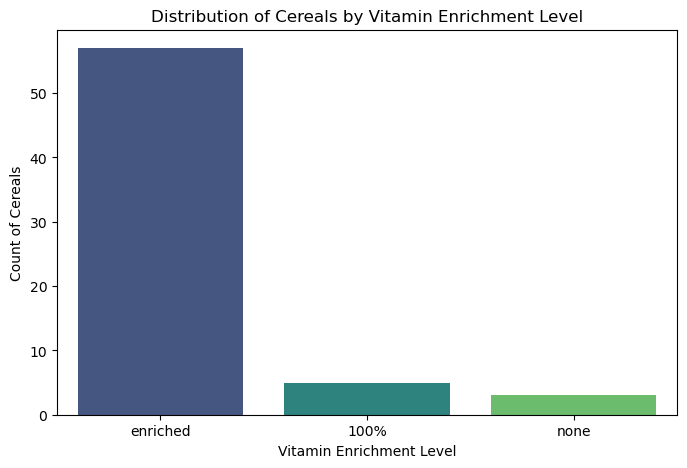

In [6]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='vitamins', palette='viridis')
plt.title('Distribution of Cereals by Vitamin Enrichment Level')
plt.xlabel('Vitamin Enrichment Level')
plt.ylabel('Count of Cereals')
plt.show()

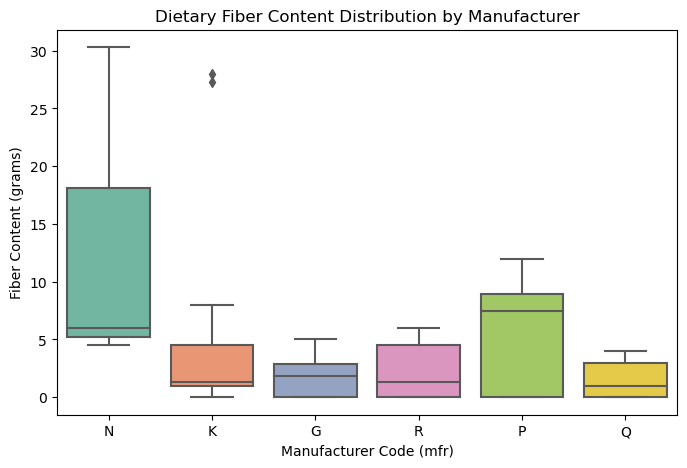

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='mfr', y='fibre', palette='Set2')
plt.title('Dietary Fiber Content Distribution by Manufacturer')
plt.xlabel('Manufacturer Code (mfr)')
plt.ylabel('Fiber Content (grams)')
plt.show()

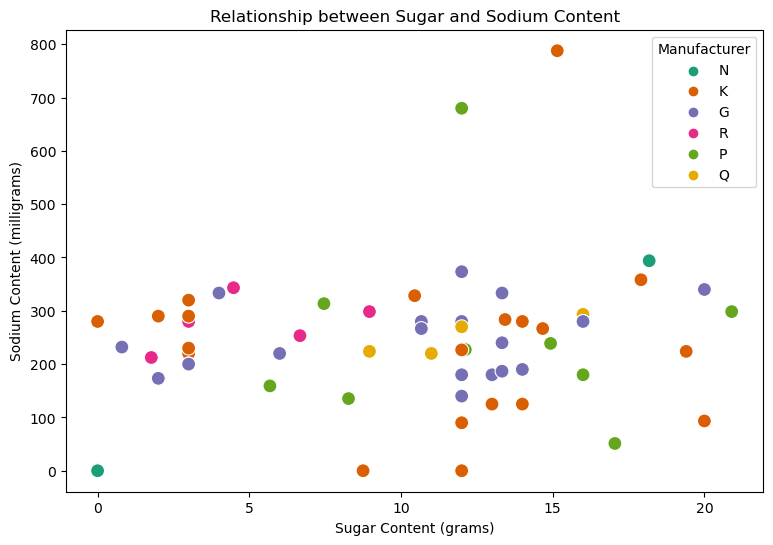

In [8]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='sugars', y='sodium', hue='mfr', palette='Dark2', s=100)
plt.title('Relationship between Sugar and Sodium Content')
plt.xlabel('Sugar Content (grams)')
plt.ylabel('Sodium Content (milligrams)')
plt.legend(title='Manufacturer')
plt.show()